# Homework 3: Machine Learning for Classification

In [67]:
# Getting the data
#!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

### Data preparation

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [69]:
# Load the dataset
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [70]:
# Columns in the dataset
for i, col in enumerate(df.columns, start=1):
    print(f"{i:>2}. {col:<30} {str(df[col].dtype):>10}")

 1. lead_source                           str
 2. industry                              str
 3. employment_status                     str
 4. location                              str
 5. annual_income                     float64
 6. number_of_courses_viewed            int64
 7. interaction_count                   int64
 8. lead_score                        float64
 9. converted                           int64


| # | Variable | Description |
|---:|---|---|
| 1 | `lead_source` | The source through which the lead arrived on the platform (organic search, social media, paid ads, referrals, etc.) |
| 2 | `industry` | The lead's industry or business sector (technology, finance, education, healthcare, etc.) |
| 3 | `employment_status` | The lead's employment status (employed, student, unemployed, self-employed, etc.) |
| 4 | `location` | The geographical region where the lead is located (Africa, Europe, Asia, North America, etc.) |
| 5 | `annual_income` | The lead's annual income |
| 6 | `number_of_courses_viewed` | The number of courses viewed by the lead |
| 7 | `interaction_count` | The number of interactions the lead had with the platform |
| 8 | `lead_score` | A score representing the lead's level of interest or quality |
| 9 | `converted` | Indicates whether the lead signed up for the platform (`1`) or not (`0`). **Target variable** for the classification task. |

In [71]:
# Checking for missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

- For categorical features, replace them with 'NA'
- For numerical features, replace with with 0.0

In [72]:
# categorical features
m_categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']

# numrical features
m_numerical_cols = ['annual_income', 'lead_score']

# Filling the missing values
df[m_categorical_cols] = df[m_categorical_cols].fillna('NA')
df[m_numerical_cols] = df[m_numerical_cols].fillna(0.0)

# Check if there is still missing values
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Question 1

What is the most frequent observation (mode) for the column industry?

- NA
- technology
- healthcare
- retail


In [73]:
print(f"The most frequent observation for the column industry is: {df['industry'].mode()[0]}")

The most frequent observation for the column industry is: technology


### Correlation

Question 2

Create the correlation matrix for the numerical features of your dataset. In a correlation matrix, you compute the correlation coefficient between every pair of features.

What are the two features that have the biggest correlation?

- interaction_count and lead_score
- number_of_courses_viewed and lead_score
- number_of_courses_viewed and interaction_count
- annual_income and interaction_count

Only consider the pairs above when answering this question.

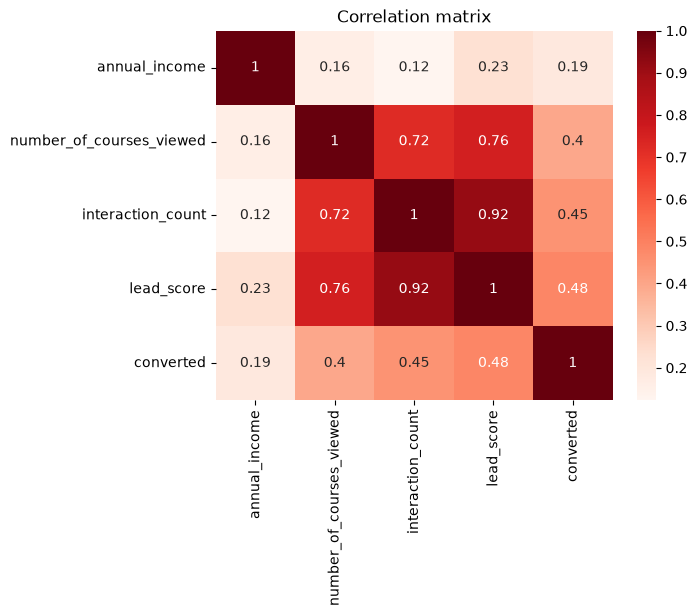

In [74]:
import seaborn as sns

# All numrical features
numerical_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']

correlation_matrix = df[numerical_cols].corr()

# Visualisation
sns.heatmap(correlation_matrix, annot=True, cmap='Reds')

plt.title("Correlation matrix")
plt.show();

interaction_count and lead_score have the biggest correlation.

### Splitting the dataset

In [75]:
from sklearn.model_selection import train_test_split

# Full Train(80%) Test(20%)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

# Train(60%) Val(20%)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

Question 3

Calculate the mutual information score between converted and other categorical variables in the dataset. Use the training set only.
Round the scores to 2 decimals using round(score, 2).

Which of these variables has the biggest mutual information score?

- industry
- location
- lead_source
- employment_status


In [76]:
from sklearn.metrics import mutual_info_score

for col in m_categorical_cols:
    score = mutual_info_score(df_train.converted, df_train[col])
    print(f"Mutual information between converted and {col:<20}: {score:>6.2f}")

Mutual information between converted and lead_source         :   0.03
Mutual information between converted and industry            :   0.00
Mutual information between converted and employment_status   :   0.02
Mutual information between converted and location            :   0.00


lead_source has the biggest mutual information score.

Question 4

Now let's train a logistic regression.
Remember that we have several categorical variables in the dataset. Include them using one-hot encoding.
Fit the model on the training dataset.
- To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:
- model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
Calculate the accuracy on the validation dataset and round it to 2 decimal digits.

What accuracy did you get?

- 0.55
- 0.65
- 0.75
- 0.85

One-hot encoding

In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Categorical columns
categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']

# Numerical columns
numerical_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

# Train set
X_train = df_train.drop(columns='converted')
y_train = df_train['converted']

# Validation set
X_val = df_val.drop(columns='converted')
y_val = df_val['converted']

# Test set
X_test = df_test.drop(columns='converted')
y_test = df_test['converted']

# Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)


# Encoding the training set
X_train_encoded = preprocessor.fit_transform(X_train)

# Encoding the validation set
X_val_encoded = preprocessor.transform(X_val)

# Encoding the test set
X_test_encoded = preprocessor.transform(X_test)

In [78]:
print(f"X_train shape:\t {X_train_encoded.shape}")
print(f"X_val shape:\t {X_val_encoded.shape}")
print(f"X_test shape:\t {X_test_encoded.shape}")

X_train shape:	 (3000, 28)
X_val shape:	 (1000, 28)
X_test shape:	 (1000, 28)


### Modeling: Logistic regression

In [79]:
from sklearn.linear_model import LogisticRegression

# Our logistic regression model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

model.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [80]:
# Making predictions on the validation set
y_pred = model.predict(X_val_encoded)

In [81]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_val, y_pred)
print(f"Accuracy score: {round(accuracy, 2)}")

Accuracy score: 0.65


Question 5

- Let's find the least useful feature using the feature elimination technique.
- Train a model using the same features and parameters as in Q4 (without rounding).
- Now exclude each feature from this set and train a model without it. Record the accuracy for each model.
- For each feature, calculate the difference between the original accuracy and the accuracy without the feature.

Which of following feature has the smallest difference?

- 'lead_source'
- 'number_of_courses_viewed'
- 'interaction_count'

Note: The difference doesn't have to be positive.


In [82]:
features_to_remove = [
    'lead_source',
    'number_of_courses_viewed',
    'interaction_count'
]

for feature in features_to_remove:

    # Remove the feature from the original data
    X_train_without = X_train.drop(columns=feature)
    X_val_without = X_val.drop(columns=feature)

    # Update categorical columns
    categorical_without = [
        col for col in categorical_cols
        if col != feature
    ]

    # New preprocessor
    preprocessor_without = ColumnTransformer(
        transformers=[
            (
                'categorical',
                OneHotEncoder(handle_unknown='ignore'),
                categorical_without
            )
        ],
        remainder='passthrough'
    )

    # Encode
    X_train_encoded_without = preprocessor_without.fit_transform(
        X_train_without
    )

    X_val_encoded_without = preprocessor_without.transform(
        X_val_without
    )

    # Train
    model_without = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000,
        random_state=42
    )

    model_without.fit(
        X_train_encoded_without,
        y_train
    )

    # Accuracy
    accuracy_without = accuracy_score(
        y_val,
        model_without.predict(X_val_encoded_without)
    )

    difference = accuracy - accuracy_without

    print(
        f"{feature}: "
        f"accuracy={accuracy_without:.4f}, "
        f"difference={difference:.4f}"
    )

lead_source: accuracy=0.6420, difference=0.0030
number_of_courses_viewed: accuracy=0.6430, difference=0.0020
interaction_count: accuracy=0.6010, difference=0.0440


Question 6

- Now let's train a regularized logistic regression.
- Let's try the following values of the parameter C: [0.000001, 0.00001, 0.0001, 0.001].
- Train models using all the features as in Q4.
- Calculate the accuracy on the validation dataset and round it to 3 decimal digits.

Which of these C leads to the best accuracy on the validation set?

- 0.000001
- 0.00001
- 0.0001
- 0.001

Note: If there are multiple options, select the smallest C

In [83]:
C_values = [0.000001, 0.00001, 0.0001, 0.001]

for C in C_values:

    model = LogisticRegression(
        solver='liblinear',
        C=C,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_encoded, y_train)

    y_pred = model.predict(X_val_encoded)

    accuracy = accuracy_score(y_val, y_pred)

    print(f"C={C}: accuracy={accuracy:.3f}")

C=1e-06: accuracy=0.598
C=1e-05: accuracy=0.598
C=0.0001: accuracy=0.613
C=0.001: accuracy=0.645


END OF THE HOMEWORK

---

My own continuation:

In [84]:
# Combine training & validation set
X_full_train = preprocessor.transform(df_full_train.drop(columns='converted'))
y_full_train = df_full_train['converted']

print("="*31)
print(f"Training set's shape: {X_full_train.shape}")
print(f"Test set's shape: {X_test_encoded.shape}")
print("="*31)

Training set's shape: (4000, 28)
Test set's shape: (1000, 28)


In [85]:
# modele
model = LogisticRegression(solver='liblinear', C=0.001, max_iter=1000, random_state=42)

# training the model
model.fit(X_full_train, y_full_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.001
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,

In [86]:
# Making predictions
y_pred = model.predict(X_test_encoded)

In [87]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.71      0.29      0.41       400
           1       0.66      0.92      0.77       600

    accuracy                           0.67      1000
   macro avg       0.69      0.61      0.59      1000
weighted avg       0.68      0.67      0.63      1000



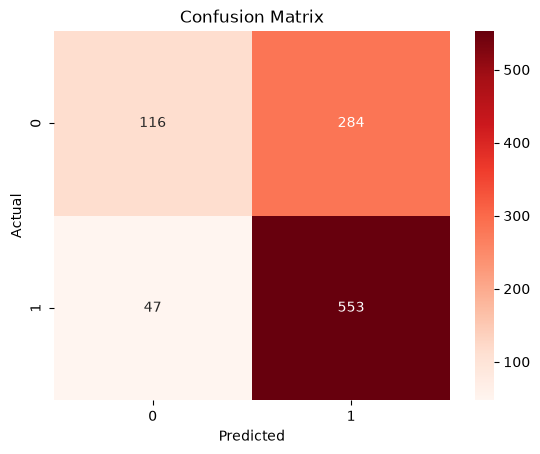

In [88]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# confusion matrix
cm = confusion_matrix(y_test, y_pred)

# visualization
sns.heatmap(cm, cmap='Reds',fmt='d', annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show();

### Optimization using optuna

In [89]:
import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Objective function
def objective(trial):

    # Hyperparameters
    C = trial.suggest_float('C', 1e-6, 10, log=True)
    solver = trial.suggest_categorical('solver', ['liblinear', 'lbfgs', 'newton-cholesky'])
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced'])

    # Logistic regression model
    model = LogisticRegression(
        C=C,
        solver=solver,
        class_weight=class_weight,
        max_iter=2000,
        random_state=42
    )

    # Training the model
    model.fit(X_train_encoded, y_train)

    # Making predictions
    y_pred = model.predict(X_val_encoded)

    # Accuracy score
    accuracy = accuracy_score(y_val, y_pred)

    return accuracy

In [90]:
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=100)

[I 2026-10-08 14:34:14,772] A new study created in memory with name: no-name-4708b6e3-791a-4052-acef-2f9c98f60240
[I 2026-10-08 14:34:14,819] Trial 0 finished with value: 0.598 and parameters: {'C': 1.068198928419079e-06, 'solver': 'newton-cholesky', 'class_weight': 'balanced'}. Best is trial 0 with value: 0.598.
[I 2026-10-08 14:34:18,594] Trial 1 finished with value: 0.724 and parameters: {'C': 0.14035883214957134, 'solver': 'lbfgs', 'class_weight': None}. Best is trial 1 with value: 0.724.
[I 2026-10-08 14:34:21,083] Trial 2 finished with value: 0.712 and parameters: {'C': 0.03914206961200975, 'solver': 'lbfgs', 'class_weight': 'balanced'}. Best is trial 1 with value: 0.724.
[I 2026-10-08 14:34:21,417] Trial 3 finished with value: 0.707 and parameters: {'C': 0.00020798812120169908, 'solver': 'lbfgs', 'class_weight': None}. Best is trial 1 with value: 0.724.
[I 2026-10-08 14:34:21,716] Trial 4 finished with value: 0.702 and parameters: {'C': 0.00016403138279968784, 'solver': 'lbfgs',

In [91]:
print("Best accuracy:", study.best_value)
print("Best parameters:")
print(study.best_params)

Best accuracy: 0.731
Best parameters:
{'C': 1.1857240600146912, 'solver': 'newton-cholesky', 'class_weight': None}


In [92]:
# Final model
classifier = LogisticRegression(C=1.1857240600146912, solver='newton-cholesky', max_iter=2000, random_state=42)

# Training
classifier.fit(X_full_train, y_full_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.1857240600146912
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'newton-cholesky'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=Non

In [93]:
# Making prediction
y_pred = classifier.predict(X_test_encoded)

# reports
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.68      0.60      0.64       400
           1       0.75      0.81      0.78       600

    accuracy                           0.73      1000
   macro avg       0.72      0.70      0.71      1000
weighted avg       0.72      0.73      0.72      1000



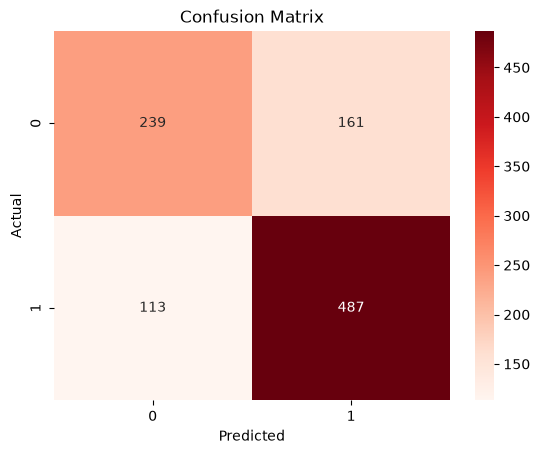

In [94]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)

# visualization
sns.heatmap(cm, cmap='Reds',fmt='d', annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show();

---